# 04 Analysis

SQL analysis of NYC restaurant inspections, answering:
- **Q1:** Do inspection scores bunch just below the A-grade threshold (13 points)?
- **Q2:** Does a restaurant's grade predict the outcome of its next inspection?
- **Q3:** Are violations concentrated in a small share of restaurants and violation types?
- **Q4:** Which restaurants should be inspected first to catch the most serious problems?

In [1]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


### connect data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

engine = create_engine("postgresql+psycopg2://localhost:5433/nyc_restaurants")

def q(sql):
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

## Q1: Score bunching at the A-grade threshold

An initial inspection scoring 0–13 earns an A immediately; 14 or more triggers a re-inspection. If restaurants or inspectors respond to this threshold, we would expect unusually many scores at 13 and unusually few at 14.

In [3]:
dist = q("""
SELECT score, COUNT(*) AS n
FROM inspections
WHERE in_scope
  AND inspection_stage = 'Initial Inspection'
  AND score IS NOT NULL
GROUP BY score
ORDER BY score;
""")

print("total initial inspections:", dist["n"].sum())
dist.head(20)

total initial inspections: 56872


,score,n
0,0,489
1,2,1963
2,3,726
3,4,1104
4,5,2026
5,6,595
6,7,3029
7,8,1516
8,9,2803
9,10,3758


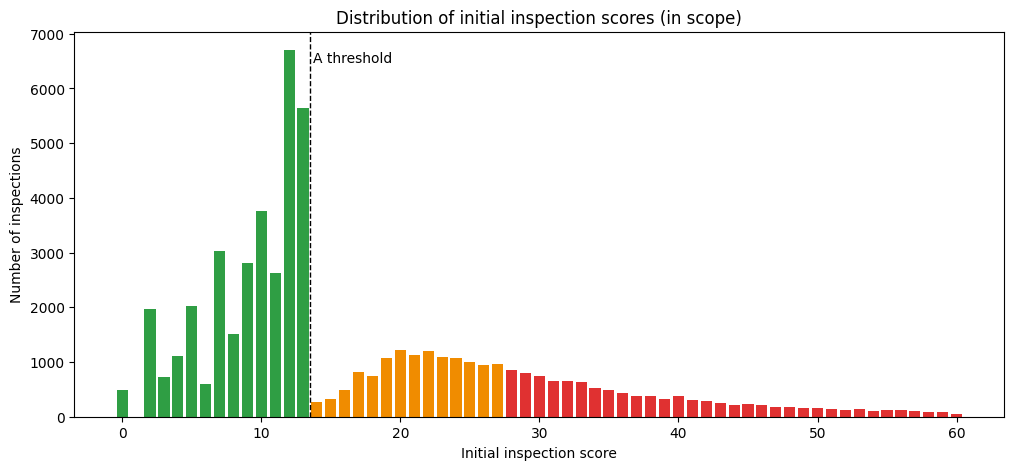

In [4]:
def band_color(score):
    """Color by grade band: A (0-13), B (14-27), C (28+)."""
    if score <= 13:
        return "#2f9e44"
    if score <= 27:
        return "#f08c00"
    return "#e03131"

plot_df = dist[dist["score"] <= 60]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(plot_df["score"], plot_df["n"], color=[band_color(s) for s in plot_df["score"]])
ax.axvline(13.5, color="black", linestyle="--", linewidth=1)
ax.text(13.7, ax.get_ylim()[1] * 0.92, "A threshold", fontsize=10)

ax.set_xlabel("Initial inspection score")
ax.set_ylabel("Number of inspections")
ax.set_title("Distribution of initial inspection scores (in scope)")
plt.savefig("../figures/q1_initial_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
zoom = dist[dist["score"].between(9, 18)].copy()
zoom["pct_of_all"] = (zoom["n"] / dist["n"].sum() * 100).round(2)
zoom

,score,n,pct_of_all
8,9,2803,4.93
9,10,3758,6.61
10,11,2618,4.60
11,12,6702,11.78
12,13,5642,9.92
13,14,261,0.46
14,15,319,0.56
15,16,483,0.85
16,17,812,1.43
17,18,737,1.30


In [6]:
ratio = dist[dist["score"] <= 40].copy()
ratio["next_n"] = ratio["n"].shift(-1)
ratio["ratio_to_next"] = (ratio["n"] / ratio["next_n"]).round(2)

ratio.sort_values("ratio_to_next", ascending=False).head(8)

,score,n,next_n,ratio_to_next
12,13,5642,261.0,21.62
4,5,2026,595.0,3.41
1,2,1963,726.0,2.70
6,7,3029,1516.0,2.00
9,10,3758,2618.0,1.44
32,33,642,533.0,1.20
11,12,6702,5642.0,1.19
37,38,370,316.0,1.17


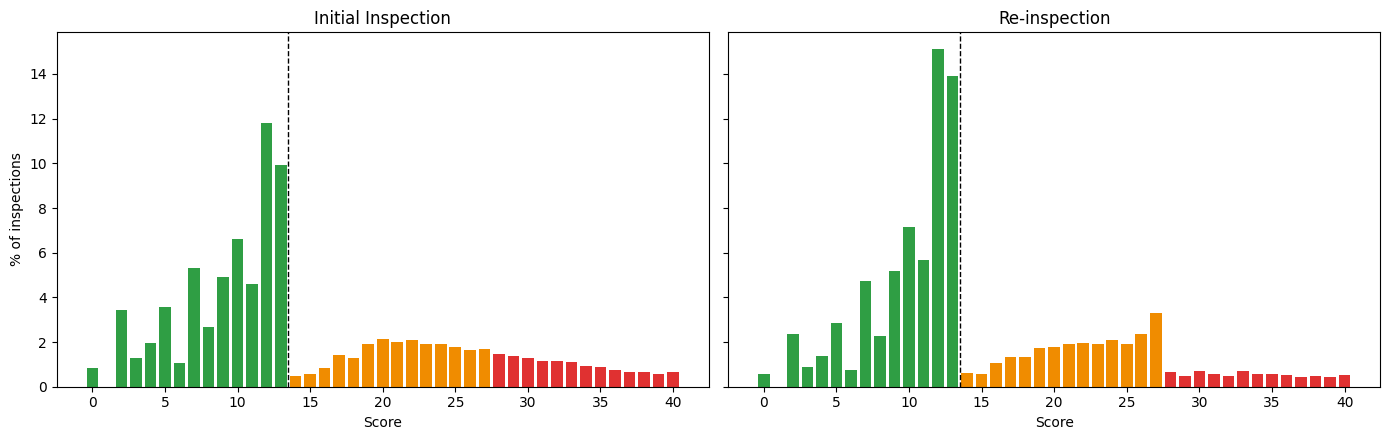

In [7]:
by_stage = q("""
SELECT inspection_stage, score, COUNT(*) AS n
FROM inspections
WHERE in_scope
  AND score IS NOT NULL
GROUP BY inspection_stage, score
ORDER BY inspection_stage, score;
""")

# Percentages use ALL scores as the denominator
by_stage["pct"] = by_stage["n"] / by_stage.groupby("inspection_stage")["n"].transform("sum") * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, stage in zip(axes, ["Initial Inspection", "Re-inspection"]):
    # Filter to 0-40 for display only
    d = by_stage[(by_stage["inspection_stage"] == stage) & (by_stage["score"] <= 40)]
    ax.bar(d["score"], d["pct"], color=[band_color(s) for s in d["score"]])
    ax.axvline(13.5, color="black", linestyle="--", linewidth=1)
    ax.set_title(stage)
    ax.set_xlabel("Score")
axes[0].set_ylabel("% of inspections")
plt.tight_layout()
plt.savefig("../figures/q1_initial_vs_reinspection.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Compare the B/C threshold (27 vs 28) across stages
threshold_check = by_stage[by_stage["score"].isin([26, 27, 28, 29])].pivot(
    index="score", columns="inspection_stage", values="pct"
).round(2)
threshold_check

inspection_stage,Initial Inspection,Re-inspection
score,,
26,1.65,2.34
27,1.69,3.30
28,1.49,0.64
29,1.39,0.47


In [9]:
by_stage[by_stage["score"].isin([12, 13])].groupby("inspection_stage")["pct"].sum().round(1)

inspection_stage
Initial Inspection    21.7
Re-inspection         29.0
Name: pct, dtype: float64

### Q1 Findings

- **Strong bunching at the A threshold.** Scores of 12 and 13 account for 21.7% of all initial inspections, while 14 accounts for only 0.46%. The drop from 13 to 14 (21.6x) is more than six times larger than any other adjacent-score drop (next largest: 3.4x).
- **Bunching is stronger when stakes are higher.** Scores of 12–13 make up 29.0% of re-inspections, which determine the posted grade, versus 21.7% of initial inspections.
- **The B/C threshold appears only where it matters.** In re-inspections, a score of 27 (grade B) is 5.2x as common as 28 (grade C). In initial inspections, where 27 and 28 lead to the same outcome, the ratio is only 1.1x. Since point values are identical in both stages, this pattern cannot be explained by how violation points add up.
- **Implication:** Posted grades likely overstate food safety for restaurants just below each threshold. A restaurant with an A at 13 points may not be meaningfully different from one at 14 points that had to be re-inspected.
- **Limitation:** The data show *that* scores bunch at thresholds, not *why*. Possible mechanisms include inspector discretion in assigning points and restaurants correcting issues during inspections; the data cannot distinguish between them.

## Q2: Does a grade predict the next inspection?

If grades reflect real differences in food safety, restaurants graded A should perform better at their next unannounced initial inspection than those graded B or C.

In [10]:
q2 = q("""
WITH graded AS (
    SELECT camis, inspection_date, grade
    FROM inspections
    WHERE in_scope
      AND grade IN ('A', 'B', 'C')
      AND NOT grade_score_mismatch
),
initials AS (
    SELECT camis, inspection_date, score, n_critical
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
      AND score IS NOT NULL
)
SELECT
    g.grade,
    COUNT(*)                                                         AS n_pairs,
    ROUND(AVG(nxt.score), 1)                                         AS avg_next_score,
    ROUND(100.0 * AVG(CASE WHEN nxt.score >= 14 THEN 1 ELSE 0 END), 1) AS pct_next_not_a,
    ROUND(100.0 * AVG(CASE WHEN nxt.score >= 28 THEN 1 ELSE 0 END), 1) AS pct_next_28_plus,
    ROUND(AVG(nxt.n_critical), 2)                                    AS avg_next_critical,
    PERCENTILE_CONT(0.5) WITHIN GROUP (
        ORDER BY nxt.inspection_date - g.inspection_date
    )                                                                AS median_days_to_next
FROM graded AS g
JOIN LATERAL (
    SELECT i.score, i.n_critical, i.inspection_date
    FROM initials AS i
    WHERE i.camis = g.camis
      AND i.inspection_date > g.inspection_date
    ORDER BY i.inspection_date
    LIMIT 1
) AS nxt ON TRUE
GROUP BY g.grade
ORDER BY g.grade;
""")
q2

,grade,n_pairs,avg_next_score,pct_next_not_a,pct_next_28_plus,avg_next_critical,median_days_to_next
0,A,25203,16.3,34.7,15.1,1.73,488.0
1,B,2888,23.6,61.6,32.1,2.57,431.0
2,C,1533,25.6,64.5,36.1,2.74,199.0


In [11]:
q2_bands = q("""
WITH graded AS (
    SELECT camis, inspection_date, grade, score
    FROM inspections
    WHERE in_scope
      AND grade IN ('A', 'B', 'C')
      AND NOT grade_score_mismatch
),
initials AS (
    SELECT camis, inspection_date, score, n_critical
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
      AND score IS NOT NULL
)
SELECT
    CASE
        WHEN g.score <= 6  THEN '1) A: 0-6'
        WHEN g.score <= 9  THEN '2) A: 7-9'
        WHEN g.score <= 11 THEN '3) A: 10-11'
        WHEN g.score <= 13 THEN '4) A: 12-13'
        WHEN g.score <= 19 THEN '5) B: 14-19'
        WHEN g.score <= 27 THEN '6) B: 20-27'
        ELSE                    '7) C: 28+'
    END                                                                AS score_band,
    COUNT(*)                                                           AS n_pairs,
    ROUND(AVG(nxt.score), 1)                                           AS avg_next_score,
    ROUND(100.0 * AVG(CASE WHEN nxt.score >= 14 THEN 1 ELSE 0 END), 1) AS pct_next_not_a,
    PERCENTILE_CONT(0.5) WITHIN GROUP (
        ORDER BY nxt.inspection_date - g.inspection_date
    )                                                                  AS median_days_to_next
FROM graded AS g
JOIN LATERAL (
    SELECT i.score, i.n_critical, i.inspection_date
    FROM initials AS i
    WHERE i.camis = g.camis
      AND i.inspection_date > g.inspection_date
    ORDER BY i.inspection_date
    LIMIT 1
) AS nxt ON TRUE
GROUP BY score_band
ORDER BY score_band;
""")
q2_bands

,score_band,n_pairs,avg_next_score,pct_next_not_a,median_days_to_next
0,1) A: 0-6,4886,13.2,24.4,497.0
1,2) A: 7-9,5414,15.2,31.1,502.0
2,3) A: 10-11,4928,16.7,35.3,493.0
3,4) A: 12-13,9975,18.2,41.4,476.0
4,5) B: 14-19,874,23.1,59.7,438.5
5,6) B: 20-27,2014,23.9,62.4,427.0
6,7) C: 28+,1533,25.6,64.5,199.0


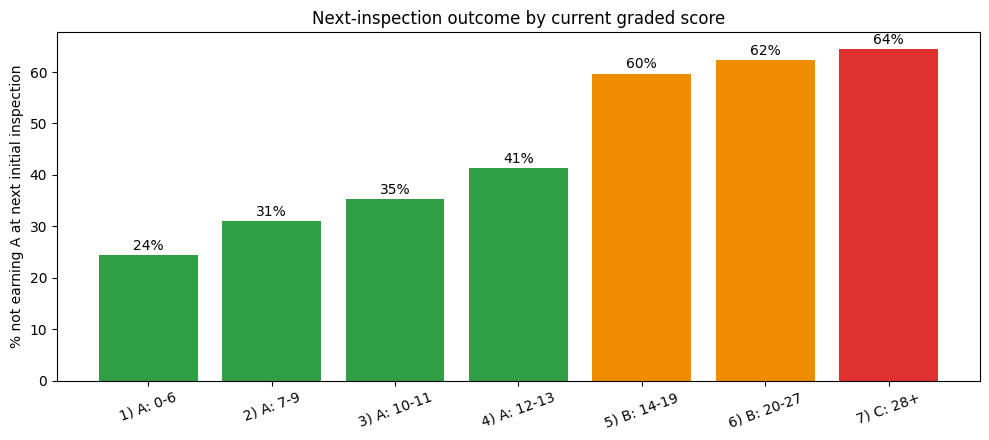

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#2f9e44"] * 4 + ["#f08c00"] * 2 + ["#e03131"]
ax.bar(q2_bands["score_band"], q2_bands["pct_next_not_a"], color=colors)

for i, v in enumerate(q2_bands["pct_next_not_a"]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=10)

ax.set_ylabel("% not earning A at next initial inspection")
ax.set_title("Next-inspection outcome by current graded score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../figures/q2_next_outcome_by_score_band.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
q2_stage = q("""
WITH graded AS (
    SELECT camis, inspection_date, grade, score, inspection_stage
    FROM inspections
    WHERE in_scope
      AND grade IN ('A', 'B', 'C')
      AND NOT grade_score_mismatch
),
initials AS (
    SELECT camis, inspection_date, score
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
      AND score IS NOT NULL
)
SELECT
    g.inspection_stage                                                 AS graded_at,
    CASE
        WHEN g.score <= 9  THEN '1) A: 0-9'
        WHEN g.score <= 11 THEN '2) A: 10-11'
        WHEN g.score <= 13 THEN '3) A: 12-13'
        WHEN g.score <= 19 THEN '4) B: 14-19'
        WHEN g.score <= 27 THEN '5) B: 20-27'
        ELSE                    '6) C: 28+'
    END                                                                AS score_band,
    COUNT(*)                                                           AS n_pairs,
    ROUND(AVG(nxt.score), 1)                                           AS avg_next_score,
    ROUND(100.0 * AVG(CASE WHEN nxt.score >= 14 THEN 1 ELSE 0 END), 1) AS pct_next_not_a,
    PERCENTILE_CONT(0.5) WITHIN GROUP (
        ORDER BY nxt.inspection_date - g.inspection_date
    )                                                                  AS median_days_to_next
FROM graded AS g
JOIN LATERAL (
    SELECT i.score, i.inspection_date
    FROM initials AS i
    WHERE i.camis = g.camis
      AND i.inspection_date > g.inspection_date
    ORDER BY i.inspection_date
    LIMIT 1
) AS nxt ON TRUE
GROUP BY graded_at, score_band
ORDER BY graded_at, score_band;
""")
q2_stage

,graded_at,score_band,n_pairs,avg_next_score,pct_next_not_a,median_days_to_next
0,Initial Inspection,1) A: 0-9,7405,13.1,23.3,510.0
1,Initial Inspection,2) A: 10-11,3212,15.3,30.2,504.0
2,Initial Inspection,3) A: 12-13,6209,16.7,35.7,487.0
3,Re-inspection,1) A: 0-9,2895,17.3,39.7,464.0
4,Re-inspection,2) A: 10-11,1716,19.3,44.9,467.0
5,Re-inspection,3) A: 12-13,3766,20.8,50.8,455.0
6,Re-inspection,4) B: 14-19,874,23.1,59.7,438.5
7,Re-inspection,5) B: 20-27,2014,23.9,62.4,427.0
8,Re-inspection,6) C: 28+,1533,25.6,64.5,199.0


### Q2 Findings

- **Grades carry real information.** Restaurants graded A fail to earn an A at their next initial inspection 34.7% of the time, versus 61.6% for B and 64.5% for C.
- **B and C are nearly indistinguishable.** Once a restaurant falls into B or C, its score barely predicts the next outcome (59.7% for B 14–19, 62.4% for B 20–27, 64.5% for C), even though C restaurants are re-inspected much sooner (median 199 vs 431 days).
- **A is not uniform.** Among restaurants that earned an A on their first try, those at 12–13 points fail their next initial inspection 35.7% of the time, versus 23.3% for those at 0–9 points.
- **Most of the apparent A/B gap reflects inspection history, not the threshold.** Across all grades, the gap between A at 12–13 and B at 14–19 is 19 points. Restricting to re-inspections, where both groups failed their initial inspection, the gap shrinks to 8.9 points (50.8% vs 59.7%), only slightly larger than the steps within A.
- **Inspection history is a stronger signal than the posted grade.** Restaurants that earned an A only on re-inspection, even with a low score (0–9), fail their next initial inspection more often (39.7%) than those that barely passed on the first try (35.7%). Both display the same A.
- **Implication:** A risk-based inspection strategy should weigh whether a restaurant recently needed a re-inspection, not just its current grade.
- **Limitations:** Grade groups differ in time to next inspection; differences partly reflect regression to the mean; comparisons are descriptive and do not control for cuisine, borough, or inspector.

## Q3: Are violations concentrated?

If a small share of restaurants accounts for a large share of critical violations, inspection resources could be targeted more efficiently than under a uniform schedule.

In [14]:
concentration = q("""
WITH per_restaurant AS (
    SELECT
        camis,
        SUM(n_critical) AS critical_total,
        COUNT(*)        AS n_initial
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
    GROUP BY camis
),
ranked AS (
    SELECT
        camis,
        critical_total,
        n_initial,
        ROW_NUMBER() OVER (ORDER BY critical_total DESC)  AS rank,
        COUNT(*) OVER ()                                  AS n_restaurants,
        SUM(critical_total) OVER (
            ORDER BY critical_total DESC
            ROWS UNBOUNDED PRECEDING
        )                                                 AS cum_critical,
        SUM(critical_total) OVER ()                       AS total_critical
    FROM per_restaurant
)
SELECT
    rank,
    critical_total,
    n_initial,
    100.0 * rank / n_restaurants          AS pct_restaurants,
    100.0 * cum_critical / total_critical AS pct_critical
FROM ranked
ORDER BY rank;
""")

print("restaurants:", len(concentration))
concentration.head()

restaurants: 27008


,rank,critical_total,n_initial,pct_restaurants,pct_critical
0,1,32,5,0.003703,0.028813
1,2,30,5,0.007405,0.055825
2,3,28,4,0.011108,0.081037
3,4,27,5,0.014810,0.105348
4,5,27,4,0.018513,0.129658


In [15]:
def critical_share(top_pct):
    """Share of critical violations from the top X% of restaurants."""
    return concentration.loc[concentration["pct_restaurants"] <= top_pct, "pct_critical"].max()

for p in [1, 5, 10, 20, 50]:
    print(f"Top {p:>2}% of restaurants account for {critical_share(p):.1f}% of critical violations")

zero = (concentration["critical_total"] == 0).mean() * 100
print(f"\nRestaurants with zero critical violations at initial inspections: {zero:.1f}%")

Top  1% of restaurants account for 4.0% of critical violations
Top  5% of restaurants account for 14.7% of critical violations
Top 10% of restaurants account for 25.0% of critical violations
Top 20% of restaurants account for 41.5% of critical violations
Top 50% of restaurants account for 75.8% of critical violations

Restaurants with zero critical violations at initial inspections: 3.5%


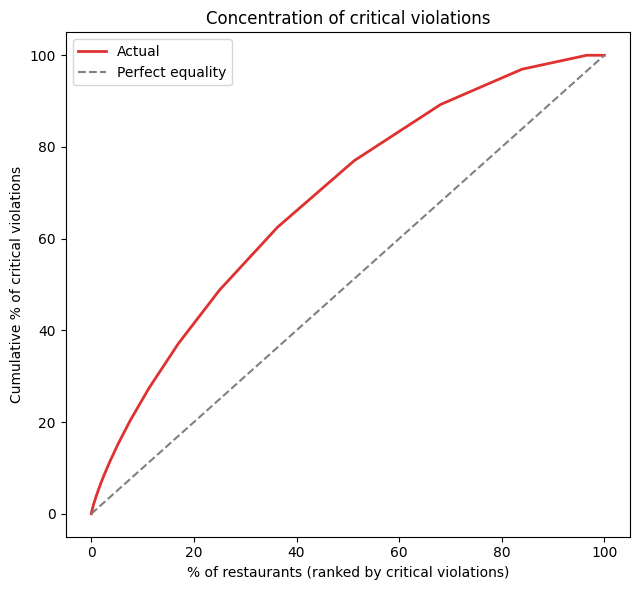

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(concentration["pct_restaurants"], concentration["pct_critical"], color="#e03131", linewidth=2, label="Actual")
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Perfect equality")

ax.set_xlabel("% of restaurants (ranked by critical violations)")
ax.set_ylabel("Cumulative % of critical violations")
ax.set_title("Concentration of critical violations")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/q3_concentration_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Split restaurants into 10 equal groups by rank, then compare inspection counts
concentration["decile"] = pd.qcut(
    concentration["rank"], 10, labels=[f"Top {i*10}%" for i in range(1, 11)]
)
concentration.groupby("decile", observed=True)[["critical_total", "n_initial"]].mean().round(2)

,critical_total,n_initial
decile,,
Top 10%,10.30,2.76
Top 20%,6.79,2.39
Top 30%,5.48,2.28
Top 40%,4.61,2.19
Top 50%,4.00,2.12
Top 60%,3.11,2.08
Top 70%,2.80,2.03
Top 80%,2.00,1.96
Top 90%,1.38,1.72


In [18]:
concentration_rate = q("""
WITH per_restaurant AS (
    SELECT
        camis,
        SUM(n_critical)                   AS critical_total,
        COUNT(*)                          AS n_initial,
        SUM(n_critical)::NUMERIC / COUNT(*) AS critical_per_initial
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
    GROUP BY camis
    HAVING COUNT(*) >= 2
),
ranked AS (
    SELECT
        critical_total,
        critical_per_initial,
        ROW_NUMBER() OVER (ORDER BY critical_per_initial DESC)  AS rank,
        COUNT(*) OVER ()                                        AS n_restaurants,
        SUM(critical_total) OVER (
            ORDER BY critical_per_initial DESC
            ROWS UNBOUNDED PRECEDING
        )                                                       AS cum_critical,
        SUM(critical_total) OVER ()                             AS total_critical
    FROM per_restaurant
)
SELECT
    rank,
    critical_per_initial,
    100.0 * rank / n_restaurants          AS pct_restaurants,
    100.0 * cum_critical / total_critical AS pct_critical
FROM ranked
ORDER BY rank;
""")

def critical_share_rate(top_pct):
    return concentration_rate.loc[concentration_rate["pct_restaurants"] <= top_pct, "pct_critical"].max()

print("restaurants with 2+ initial inspections:", len(concentration_rate))
for p in [1, 5, 10, 20, 50]:
    print(f"Top {p:>2}% by rate account for {critical_share_rate(p):.1f}% of critical violations")

restaurants with 2+ initial inspections: 20747
Top  1% by rate account for 3.0% of critical violations
Top  5% by rate account for 12.3% of critical violations
Top 10% by rate account for 21.7% of critical violations
Top 20% by rate account for 37.5% of critical violations
Top 50% by rate account for 72.4% of critical violations


### Q3a Findings: Concentration across restaurants

- **Moderate, not extreme, concentration.** The top 10% of restaurants account for 25.0% of critical violations at initial inspections, and the top 20% for 41.5%, far from an 80/20 pattern.
- **Critical violations are nearly universal.** Only 3.5% of restaurants had zero critical violations across all their initial inspections.
- **Concentration is mostly real, not an artifact of inspection frequency.** The top decile has about 1.8x as many initial inspections as the bottom decile but about 9x as many critical violations per inspection. Ranking restaurants by critical violations *per inspection* (restaurants with 2+ initial inspections) only modestly lowers concentration: the top 10% then account for 21.7%.
- **Implication:** Targeting the worst restaurants alone would miss most critical violations. Because problems are widespread, risk-based targeting should complement, not replace, routine inspections.
- **Limitation:** Most restaurants have only 2–3 initial inspections, so per-inspection rankings include some chance variation; true concentration may be slightly lower.

### Q3b: Which violation types recur?

For each violation category found at an initial inspection, how often does the same category appear again at that restaurant's next initial inspection, compared with how common the category is overall?

In [19]:
recurrence = q("""
WITH initials AS (
    SELECT
        inspection_id,
        camis,
        LEAD(inspection_id) OVER (PARTITION BY camis ORDER BY inspection_date) AS next_id
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
),
cats AS (
    SELECT DISTINCT inspection_id, violation_category
    FROM violations
),
base AS (
    SELECT
        c.violation_category,
        COUNT(*)::NUMERIC / (SELECT COUNT(*) FROM initials) AS base_rate
    FROM cats AS c
    JOIN initials AS i ON i.inspection_id = c.inspection_id
    GROUP BY c.violation_category
)
SELECT
    c.violation_category,
    COUNT(*)                                                                    AS n_with_category,
    ROUND(100.0 * AVG(CASE WHEN nc.inspection_id IS NOT NULL THEN 1 ELSE 0 END), 1) AS pct_recur_next,
    ROUND(100.0 * MAX(b.base_rate), 1)                                          AS pct_base,
    ROUND(AVG(CASE WHEN nc.inspection_id IS NOT NULL THEN 1 ELSE 0 END) / MAX(b.base_rate), 2) AS lift
FROM initials AS i
JOIN cats AS c
    ON c.inspection_id = i.inspection_id
LEFT JOIN cats AS nc
    ON nc.inspection_id = i.next_id
   AND nc.violation_category = c.violation_category
JOIN base AS b
    ON b.violation_category = c.violation_category
WHERE i.next_id IS NOT NULL
GROUP BY c.violation_category
HAVING COUNT(*) >= 500
ORDER BY lift DESC;
""")

category_labels = {
    "02": "Food temperature",
    "03": "Food source",
    "04": "Pests (evidence)",
    "05": "Handwashing facilities",
    "06": "Food contact sanitation",
    "08": "Pest harborage",
    "09": "Food contact surface design",
    "10": "Non-food contact surfaces",
    "20": "Grade card posting (admin)",
    "28": "Pest control records (admin)",
}
recurrence.insert(1, "label", recurrence["violation_category"].map(category_labels))
recurrence

,violation_category,label,n_with_category,pct_recur_next,pct_base,lift
0,03,Food source,638,10.5,2.6,4.09
1,28,Pest control records (admin),875,9.9,3.3,2.99
2,05,Handwashing facilities,2776,14.7,10.0,1.47
3,09,Food contact surface design,3422,17.1,12.4,1.38
4,02,Food temperature,11447,53.2,39.4,1.35
5,08,Pest harborage,10361,44.2,34.3,1.29
6,04,Pests (evidence),13340,51.4,44.3,1.16
7,06,Food contact sanitation,15475,57.2,53.2,1.07
8,10,Non-food contact surfaces,20828,71.9,70.3,1.02


### Q3b Findings: Recurring violation types

- **Rare violations are the most persistent.** Food from unapproved sources appears in only 2.6% of initial inspections, but restaurants cited for it see it again at their next initial inspection 10.5% of the time, 4.1x the base rate (n = 638).
- **Structural problems recur more than cleaning problems.** Handwashing facilities (lift 1.47) and food contact surface design (1.38), which require investment to fix, recur more than food contact sanitation (1.07), which can be corrected on the spot.
- **Food temperature is both common and persistent.** It appears in 39.4% of initial inspections and recurs 53.2% of the time when previously cited (lift 1.35), making it the most consequential recurring critical issue by volume.
- **The most common category carries almost no signal.** Non-food contact surfaces appear in 70.3% of initial inspections, and a prior citation barely changes the chance of another (lift 1.02).
- **Implication:** Prior citations for food source, handwashing facilities, and food temperature are useful risk signals for prioritizing inspections; facility-maintenance citations are not.
- **Limitation:** Lift compares against all initial inspections. Part of the elevated recurrence may reflect overall restaurant quality rather than persistence of a specific violation type.

## Q4: Risk-based inspection prioritization

If inspection capacity is limited, which restaurants should be inspected first to catch the most serious problems? We predict whether a restaurant's next initial inspection will score 28+ (C-level) using only information available before that inspection, then compare prioritization strategies.

In [20]:
features = q("""
WITH initials AS (
    SELECT
        inspection_id,
        camis,
        inspection_date,
        score,
        LAG(inspection_id)   OVER w      AS prev_id,
        LAG(score)           OVER w      AS prev_score,
        LAG(n_critical)      OVER w      AS prev_n_critical,
        LAG(inspection_date) OVER w      AS prev_date,
        ROW_NUMBER()         OVER w - 1  AS n_prior_initials,
        AVG(score) OVER (
            PARTITION BY camis ORDER BY inspection_date
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
        )                                AS avg_prior_score
    FROM inspections
    WHERE in_scope
      AND inspection_stage = 'Initial Inspection'
      AND score IS NOT NULL
    WINDOW w AS (PARTITION BY camis ORDER BY inspection_date)
),
prev_cats AS (
    SELECT
        inspection_id,
        BOOL_OR(violation_category = '02')          AS prev_temp,
        BOOL_OR(violation_category = '03')          AS prev_source,
        BOOL_OR(violation_category = '05')          AS prev_handwash,
        BOOL_OR(violation_category IN ('04', '08')) AS prev_pests
    FROM violations
    GROUP BY inspection_id
)
SELECT
    i.inspection_id,
    i.camis,
    i.inspection_date,
    i.score,
    (i.score >= 28)::INT                     AS target_serious,
    (i.score >= 14)::INT                     AS target_not_a,
    i.prev_score,
    i.prev_n_critical,
    (i.prev_score >= 14)::INT                AS prev_failed_initial,
    lg.grade                                 AS last_grade,
    i.inspection_date - i.prev_date          AS days_since_prev,
    i.n_prior_initials,
    ROUND(i.avg_prior_score, 2)              AS avg_prior_score,
    COALESCE(pc.prev_temp, FALSE)::INT       AS prev_temp,
    COALESCE(pc.prev_source, FALSE)::INT     AS prev_source,
    COALESCE(pc.prev_handwash, FALSE)::INT   AS prev_handwash,
    COALESCE(pc.prev_pests, FALSE)::INT      AS prev_pests
FROM initials AS i
LEFT JOIN prev_cats AS pc
    ON pc.inspection_id = i.prev_id
LEFT JOIN LATERAL (
    SELECT g.grade
    FROM inspections AS g
    WHERE g.camis = i.camis
      AND g.in_scope
      AND g.grade IN ('A', 'B', 'C')
      AND g.inspection_date < i.inspection_date
    ORDER BY g.inspection_date DESC
    LIMIT 1
) AS lg ON TRUE
WHERE i.prev_id IS NOT NULL
ORDER BY i.inspection_date;
""")

print(features.shape)
features.head()

(29864, 17)


,inspection_id,camis,inspection_date,score,target_serious,target_not_a,prev_score,prev_n_critical,prev_failed_initial,last_grade,days_since_prev,n_prior_initials,avg_prior_score,prev_temp,prev_source,prev_handwash,prev_pests
0,10721,41331528,2010-04-29,17,0,1,35,2,1,None,62,1,35.0,0,0,1,1
1,10722,41331528,2011-06-16,20,0,1,17,2,1,None,413,2,26.0,0,0,0,1
2,10724,41331528,2012-01-20,18,0,1,20,2,1,A,218,3,24.0,0,0,0,1
3,21990,50003303,2014-09-13,19,0,1,5,0,0,A,191,1,5.0,0,0,0,1
4,21994,50003303,2015-02-11,2,0,0,19,2,1,C,151,2,12.0,0,0,0,1


In [21]:
# Overall target rates
print(features[["target_serious", "target_not_a"]].mean().round(3))

# Rows and target rate by year (to plan the train/test split)
features["year"] = pd.to_datetime(features["inspection_date"]).dt.year
print(features.groupby("year").agg(
    n=("target_serious", "size"),
    serious_rate=("target_serious", "mean"),
).round(3))

# First look at the key signal from Q2
features.groupby("prev_failed_initial")["target_serious"].agg(["size", "mean"]).round(3)

target_serious    0.18
target_not_a      0.39
dtype: float64
          n  serious_rate
year                     
2010      1         0.000
2011      1         0.000
2012      1         0.000
2014      1         0.000
2015      1         0.000
2016      4         0.250
2017     42         0.024
2018    104         0.106
2019    127         0.118
2020     22         0.136
2021      3         0.333
2022     37         0.297
2023    552         0.165
2024   5016         0.157
2025  11292         0.178
2026  12660         0.193


,size,mean
prev_failed_initial,,
0,17692,0.124
1,12172,0.262


### Q4.2: Train/test split and baseline strategies

Train on inspections before 2026; test on 2026 inspections. Each strategy ranks test inspections by risk. We measure the **capture rate**: if only the top X% are prioritized, what share of all serious failures (score 28+) do we find?

In [22]:
import numpy as np

features["inspection_date"] = pd.to_datetime(features["inspection_date"])

train = features[features["inspection_date"] < "2026-01-01"].copy()
test = features[features["inspection_date"] >= "2026-01-01"].copy()

print(f"train: {len(train):>6} rows   serious rate: {train['target_serious'].mean():.3f}")
print(f"test:  {len(test):>6} rows   serious rate: {test['target_serious'].mean():.3f}")

train:  17204 rows   serious rate: 0.170
test:   12660 rows   serious rate: 0.193


In [23]:
def capture_rate(df, score_col, top_pct, target="target_serious", seed=42):
    """Share of all serious failures found if we prioritize the top X% ranked by score_col."""
    rng = np.random.default_rng(seed)
    ranked = (
        df.assign(_tiebreak=rng.random(len(df)))
        .sort_values([score_col, "_tiebreak"], ascending=False)
    )
    k = int(len(ranked) * top_pct / 100)
    return ranked[target].iloc[:k].sum() / ranked[target].sum() * 100

In [24]:
test["random"] = np.random.default_rng(0).random(len(test))
test["grade_rank"] = test["last_grade"].map({"C": 3, "B": 2, "A": 0}).fillna(1)

strategies = {
    "Random": "random",
    "Last grade (C > B > ungraded > A)": "grade_rank",
    "Rule 1: failed last initial": "prev_failed_initial",
    "Rule 2: last initial score": "prev_score",
}

rows = []
for name, col in strategies.items():
    row = {"strategy": name}
    for p in [10, 20, 30]:
        row[f"top {p}%"] = round(capture_rate(test, col, p), 1)
    rows.append(row)

results = pd.DataFrame(rows)
results

,strategy,top 10%,top 20%,top 30%
0,Random,10.8,21.5,31.8
1,Last grade (C > B > ungraded > A),18.1,31.4,40.2
2,Rule 1: failed last initial,14.2,28.8,42.5
3,Rule 2: last initial score,17.8,32.4,45.4


### Q4.3: Logistic regression

Combine all history-based features into one risk score and compare it with the simple rules.

In [25]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

NUMERIC_FEATURES = [
    "prev_score", "prev_n_critical", "prev_failed_initial",
    "days_since_prev", "n_prior_initials", "avg_prior_score",
    "prev_temp", "prev_source", "prev_handwash", "prev_pests",
]

def make_X(df):
    """Build the model input: numeric features plus one-hot encoded last grade."""
    X = df[NUMERIC_FEATURES].copy()
    grades = df["last_grade"].fillna("None")
    for g in ["B", "C", "None"]:
        X[f"last_grade_{g}"] = (grades == g).astype(int)
    return X

X_train, y_train = make_X(train), train["target_serious"]
X_test, y_test = make_X(test), test["target_serious"]

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

test["model_risk"] = model.predict_proba(X_test)[:, 1]
print("AUC:", round(roc_auc_score(y_test, test["model_risk"]), 3))

AUC: 0.672


/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * 

In [27]:
strategies["Logistic regression"] = "model_risk"

rows = []
for name, col in strategies.items():
    row = {"strategy": name}
    for p in [10, 20, 30]:
        row[f"top {p}%"] = round(capture_rate(test, col, p), 1)
    rows.append(row)

results = pd.DataFrame(rows)
results

,strategy,top 10%,top 20%,top 30%
0,Random,10.8,21.5,31.8
1,Last grade (C > B > ungraded > A),18.1,31.4,40.2
2,Rule 1: failed last initial,14.2,28.8,42.5
3,Rule 2: last initial score,17.8,32.4,45.4
4,Logistic regression,19.9,35.8,49.0


In [28]:
coefs = pd.Series(model[-1].coef_[0], index=X_train.columns).sort_values()
coefs.round(3)

prev_score            -0.349
n_prior_initials      -0.099
days_since_prev       -0.033
prev_source           -0.009
prev_failed_initial    0.007
last_grade_None        0.016
prev_handwash          0.019
prev_pests             0.111
prev_temp              0.143
last_grade_B           0.153
last_grade_C           0.174
prev_n_critical        0.215
avg_prior_score        0.427
dtype: float64

In [29]:
print("coefficients finite:", np.isfinite(model[-1].coef_).all())
print("predictions finite: ", np.isfinite(test["model_risk"]).all())

coefficients finite: True
predictions finite:  True


In [30]:
FEATURES_REDUCED = [f for f in NUMERIC_FEATURES if f not in ["prev_score", "prev_failed_initial"]]

def make_X_reduced(df):
    X = df[FEATURES_REDUCED].copy()
    grades = df["last_grade"].fillna("None")
    for g in ["B", "C", "None"]:
        X[f"last_grade_{g}"] = (grades == g).astype(int)
    return X

model_reduced = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model_reduced.fit(make_X_reduced(train), y_train)
test["model_reduced_risk"] = model_reduced.predict_proba(make_X_reduced(test))[:, 1]

print("AUC (reduced):", round(roc_auc_score(y_test, test["model_reduced_risk"]), 3))
pd.Series(model_reduced[-1].coef_[0], index=make_X_reduced(train).columns).sort_values().round(3)

AUC (reduced): 0.668


/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/kat/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * 

n_prior_initials   -0.109
days_since_prev    -0.023
prev_source        -0.014
prev_handwash       0.002
last_grade_None     0.019
prev_pests          0.103
prev_temp           0.141
prev_n_critical     0.155
avg_prior_score     0.156
last_grade_B        0.157
last_grade_C        0.179
dtype: float64

In [31]:
strategies["Rule 3: average of past initial scores"] = "avg_prior_score"
strategies["Logistic regression (reduced)"] = "model_reduced_risk"

rows = []
for name, col in strategies.items():
    row = {"strategy": name}
    for p in [10, 20, 30]:
        row[f"top {p}%"] = round(capture_rate(test, col, p), 1)
    rows.append(row)

results = pd.DataFrame(rows)
results

,strategy,top 10%,top 20%,top 30%
0,Random,10.8,21.5,31.8
1,Last grade (C > B > ungraded > A),18.1,31.4,40.2
2,Rule 1: failed last initial,14.2,28.8,42.5
3,Rule 2: last initial score,17.8,32.4,45.4
4,Logistic regression,19.9,35.8,49.0
5,Rule 3: average of past initial scores,18.8,33.5,47.4
6,Logistic regression (reduced),19.4,35.3,48.4


### Q4 Findings

- **Inspection history predicts serious failures, but only moderately.** A logistic regression using only prior inspection history reaches an AUC of 0.67 on 2026 inspections (trained on earlier years), consistent with the large chance component found in Q2 and Q3.
- **Risk-based prioritization finds more problems with the same effort.** Prioritizing the top 20% of inspections by model risk captures 35.8% of serious failures (score 28+), versus 21.5% under random selection and 31.4% under ordering by current grade. In the 2026 test period, that is roughly 875 serious failures found versus about 767 under grade-based ordering.
- **A one-line rule captures most of the gain.** Ranking by the average of a restaurant's past initial inspection scores captures 33.5% in the top 20%, about 84% of the model's improvement over random, with no modeling infrastructure required.
- **Binary signals are weak for ranking.** "Failed last initial inspection" doubles the serious failure rate (26.2% vs 12.4%), but because 41% of inspections share it, it ranks worse than continuous score-based rules at the top of the list.
- **What matters:** past scores, prior critical violations, B/C grades, and prior temperature and pest violations all raise risk, consistent with Q2 and Q3b. Rare signals such as unapproved food sources add little at the population level.
- **Recommendation:** Pilot a simple score-based priority list (average past initial score), and consider the model once data infrastructure supports regular retraining. Risk-based targeting should complement, not replace, routine inspections, since critical violations are nearly universal (Q3a).
- **Limitations:** Predictions reflect historical patterns and cannot capture how restaurants would respond to a new inspection schedule. Borough and cuisine were deliberately excluded to avoid systematically over-inspecting certain neighborhoods. The serious failure rate rose from 15.7% (2024) to 19.3% (2026), so model performance may shift over time.

## Export for Tableau

Export dashboard-ready tables to `data/tableau/`. Tableau Public reads files rather than a live database connection.

In [32]:
import os

TABLEAU_DIR = "../data/tableau/"
os.makedirs(TABLEAU_DIR, exist_ok=True)

# 1. Inspection-level table for pages 1 and 2 (score distribution, filters)
inspections_export = q("""
SELECT
    i.inspection_id,
    i.camis,
    r.dba,
    r.boro,
    r.cuisine_description,
    r.zipcode,
    r.nta,
    r.latitude,
    r.longitude,
    i.inspection_date,
    i.inspection_program,
    i.inspection_stage,
    i.score,
    i.grade,
    i.n_violations,
    i.n_critical
FROM inspections AS i
JOIN restaurants AS r
    ON i.camis = r.camis
WHERE i.in_scope
  AND i.score IS NOT NULL;
""")
inspections_export.to_csv(TABLEAU_DIR + "inspections.csv", index=False)

# 2. Next-inspection outcome by score band (page 2)
q2_stage.to_csv(TABLEAU_DIR + "next_outcome_by_band.csv", index=False)

# 3. Recurring violation types (page 3)
recurrence.to_csv(TABLEAU_DIR + "recurrence.csv", index=False)

print("inspections:", inspections_export.shape)
print("next outcome:", q2_stage.shape)
print("recurrence:", recurrence.shape)

inspections: (77125, 16)
next outcome: (9, 6)
recurrence: (9, 6)


In [33]:
curve_strategies = {
    "Random": "random",
    "Last grade": "grade_rank",
    "Average past initial score": "avg_prior_score",
    "Logistic regression": "model_risk",
}

curve_rows = []
for name, col in curve_strategies.items():
    for p in range(1, 101):
        curve_rows.append({
            "strategy": name,
            "pct_inspected": p,
            "pct_captured": round(capture_rate(test, col, p), 2),
        })

capture_curve = pd.DataFrame(curve_rows)
capture_curve.to_csv(TABLEAU_DIR + "capture_curve.csv", index=False)

print(capture_curve.shape)
capture_curve[capture_curve["pct_inspected"] == 20]

(400, 3)


,strategy,pct_inspected,pct_captured
19,Random,20,21.48
119,Last grade,20,31.44
219,Average past initial score,20,33.48
319,Logistic regression,20,35.77
